<a href="https://colab.research.google.com/github/shahzaibali-edu/Road-Accident-Hotspot-Miner/blob/main/P13_Hotspot_Miner.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import gc
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
sns.set_theme(style="whitegrid", palette="deep")

# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Data_Mining_Project/Data/US_Accidents.parquet'

# 2. Load only the columns relevant to our mining pipeline to keep peak RAM low
selected_cols = [
    # Identifiers & Target
    'ID', 'Severity',
    # Temporal & Spatial
    'Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng', 'End_Lat', 'End_Lng',
    'Distance(mi)', 'City', 'County', 'State', 'Timezone', 'Country',
    # Weather Conditions
    'Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)',
    'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)', 'Precipitation(in)',
    'Weather_Condition',
    # Road Features (Binary Flags)
    'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit',
    'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming',
    'Traffic_Signal', 'Turning_Loop',
    # Light Conditions & Free Text (for optional Expert Module)
    'Sunrise_Sunset', 'Civil_Twilight', 'Description'
]

if os.path.exists(file_path):
    print(f"Loading dataset from shared Google Drive Parquet: {file_path}")
    raw_df = pd.read_parquet(file_path, columns=selected_cols)
else:
    print("Shared Drive Parquet not found. Downloading from original Kaggle source...")
    import kagglehub
    kaggle_path = kagglehub.dataset_download("sobhanmoosavi/us-accidents")
    csv_file = os.path.join(kaggle_path, "US_Accidents_March23.csv")
    raw_df = pd.read_csv(csv_file, usecols=selected_cols, low_memory=False)

print(f"Raw Dataset Shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns")
print("\nRaw Severity Class Distribution (%):")
print((raw_df['Severity'].value_counts(normalize=True).sort_index() * 100).round(2))

# 3. Deliberate Stratified Sampling to 500,000 rows (Lecture 5, Slide 14)
SAMPLE_SIZE = 500_000
if len(raw_df) > SAMPLE_SIZE:
    df, _ = train_test_split(
        raw_df,
        train_size=SAMPLE_SIZE,
        stratify=raw_df['Severity'],
        random_state=RANDOM_SEED
    )
    df = df.reset_index(drop=True)
else:
    df = raw_df.copy()

# Free raw_df from Colab RAM immediately
del raw_df
gc.collect()

print(f"\nStratified Sample Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("Sampled Severity Class Distribution (%):")
print((df['Severity'].value_counts(normalize=True).sort_index() * 100).round(2))

Mounted at /content/drive
Loading dataset from shared Google Drive Parquet: /content/drive/MyDrive/Data_Mining_Project/Data/US_Accidents.parquet
Raw Dataset Shape: 7,728,394 rows × 39 columns

Raw Severity Class Distribution (%):
Severity
1     0.87
2    79.67
3    16.81
4     2.65
Name: proportion, dtype: float64

Stratified Sample Shape: 500,000 rows × 39 columns
Sampled Severity Class Distribution (%):
Severity
1     0.87
2    79.67
3    16.81
4     2.65
Name: proportion, dtype: float64


In [ ]:
# 1. Drop post-accident target-leakage columns and zero-variance constant columns
leakage_and_constant_cols = ['End_Time', 'End_Lat', 'End_Lng', 'Country', 'Turning_Loop']
df = df.drop(columns=[c for c in leakage_and_constant_cols if c in df.columns])
print(f"Dropped leakage & constant columns: {leakage_and_constant_cols}")
print(f"Remaining columns: {df.shape[1]}")

# 2. Programmatic Data Dictionary & Attribute Type Summary Table
attribute_type_map = {
    'ID': ('Nominal (Identifier)', 'Discrete', 'None (Row ID only)'),
    'Severity': ('Ordinal (Target 1-4)', 'Discrete', 'Mode, Median, Class %'),
    'Start_Time': ('Interval (Timestamp)', 'Continuous', 'Time extraction, Range'),
    'Start_Lat': ('Interval (Spatial Coord)', 'Continuous', 'Haversine Distance, Median'),
    'Start_Lng': ('Interval (Spatial Coord)', 'Continuous', 'Haversine Distance, Median'),
    'Distance(mi)': ('Ratio (Post-impact length)', 'Continuous', 'Median, IQR, Mean, SD (EDA only)'),
    'City': ('Nominal', 'Discrete', 'Mode, Frequency'),
    'County': ('Nominal', 'Discrete', 'Mode, Frequency'),
    'State': ('Nominal', 'Discrete', 'Mode, Frequency'),
    'Timezone': ('Nominal', 'Discrete', 'Mode, Frequency'),
    'Temperature(F)': ('Interval', 'Continuous', 'Mean, SD, Median, IQR'),
    'Wind_Chill(F)': ('Interval', 'Continuous', 'Mean, SD, Median, IQR'),
    'Humidity(%)': ('Ratio', 'Continuous', 'Mean, SD, Median, IQR'),
    'Pressure(in)': ('Ratio', 'Continuous', 'Mean, SD, Median, IQR'),
    'Visibility(mi)': ('Ratio', 'Continuous', 'Median, IQR, Mean, SD'),
    'Wind_Direction': ('Nominal', 'Discrete', 'Mode, Frequency'),
    'Wind_Speed(mph)': ('Ratio', 'Continuous', 'Median, IQR, Mean, SD'),
    'Precipitation(in)': ('Ratio', 'Continuous', 'Median, IQR, Mean, SD'),
    'Weather_Condition': ('Nominal', 'Discrete', 'Mode, Frequency'),
    'Sunrise_Sunset': ('Binary (Symmetric)', 'Discrete', 'Mode, Proportions'),
    'Civil_Twilight': ('Binary (Symmetric)', 'Discrete', 'Mode, Proportions'),
    'Description': ('Text (Unstructured)', 'Discrete', 'TF-IDF / Token Frequency')
}

# Add all remaining binary road flags automatically
for col in df.columns:
    if col not in attribute_type_map:
        attribute_type_map[col] = ('Binary (Asymmetric Road Flag)', 'Discrete', 'Positive Rate (% True), Mode')

dict_rows = []
for col in df.columns:
    attr_type, disc_cont, valid_stats = attribute_type_map.get(col, ('Nominal', 'Discrete', 'Mode'))
    dict_rows.append({
        'Column': col,
        'Pandas Dtype': str(df[col].dtype),
        'Attribute Type (Lec 2)': attr_type,
        'Discrete/Continuous': disc_cont,
        'Missing (%)': round(df[col].isnull().mean() * 100, 2),
        'Unique Values': df[col].nunique(dropna=True),
        'Valid Summary Operations': valid_stats
    })

data_dictionary_df = pd.DataFrame(dict_rows)
display(data_dictionary_df)

Dropped leakage & constant columns: ['End_Time', 'End_Lat', 'End_Lng', 'Country', 'Turning_Loop']
Remaining columns: 34


,Column,Pandas Dtype,Attribute Type (Lec 2),Discrete/Continuous,Missing (%),Unique Values,Valid Summary Operations
0,ID,object,Nominal (Identifier),Discrete,0.00,500000,None (Row ID only)
1,Severity,int64,Ordinal (Target 1-4),Discrete,0.00,4,"Mode, Median, Class %"
2,Start_Time,object,Interval (Timestamp),Continuous,0.00,486993,"Time extraction, Range"
3,Start_Lat,float64,Interval (Spatial Coord),Continuous,0.00,369627,"Haversine Distance, Median"
4,Start_Lng,float64,Interval (Spatial Coord),Continuous,0.00,370845,"Haversine Distance, Median"
5,Distance(mi),float64,Ratio (Post-impact length),Continuous,0.00,10585,"Median, IQR, Mean, SD (EDA only)"
6,City,object,Nominal,Discrete,0.01,9534,"Mode, Frequency"
7,County,object,Nominal,Discrete,0.00,1593,"Mode, Frequency"
8,State,object,Nominal,Discrete,0.00,49,"Mode, Frequency"
9,Timezone,object,Nominal,Discrete,0.09,4,"Mode, Frequency"


In [ ]:
# 1. Parse Start_Time safely (handles mixed fractional seconds in US Accidents 2023)
df['Start_Time'] = pd.to_datetime(df['Start_Time'], format='mixed', errors='coerce')
invalid_time_rows = df['Start_Time'].isnull().sum()
if invalid_time_rows > 0:
    df = df.dropna(subset=['Start_Time']).reset_index(drop=True)
print(f"Dropped {invalid_time_rows} rows with unparseable Start_Time.")

# 2. Uniqueness Check: Exact ID duplicates & repeated event keys
exact_dups = df.duplicated(subset=['ID']).sum()
event_dups = df.duplicated(subset=['Start_Time', 'Start_Lat', 'Start_Lng', 'Severity']).sum()
print(f"Exact ID duplicates found: {exact_dups:,}")
print(f"Repeated event duplicates (same Time, Lat, Lng, Severity) found: {event_dups:,}")

df = df.drop_duplicates(subset=['ID'], keep='first')
df = df.drop_duplicates(subset=['Start_Time', 'Start_Lat', 'Start_Lng', 'Severity'], keep='first').reset_index(drop=True)
print(f"Shape after deduplication: {df.shape[0]:,} rows × {df.shape[1]} columns")

# 3. Consistency Check: Harmonize Wind_Direction & Weather_Condition strings
wind_map = {
    'Calm': 'CALM', 'North': 'N', 'South': 'S', 'East': 'E', 'West': 'W',
    'Variable': 'VAR', 'NNW': 'NW', 'WNW': 'NW', 'NNE': 'NE', 'ENE': 'NE',
    'SSW': 'SW', 'WSW': 'SW', 'SSE': 'SE', 'ESE': 'SE'
}
df['Wind_Direction'] = df['Wind_Direction'].astype(str).str.strip().replace({'nan': np.nan, 'None': np.nan})
df['Wind_Direction'] = df['Wind_Direction'].replace(wind_map)

def standardize_weather(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower()
    if any(k in s for k in ['thunder', 't-storm', 'storm', 'hail', 'tornado', 'squall']):
        return 'Thunderstorm'
    if any(k in s for k in ['snow', 'sleet', 'ice', 'freezing', 'wintry', 'blizzard']):
        return 'Snow_Ice'
    if any(k in s for k in ['rain', 'drizzle', 'shower', 'precipitation']):
        return 'Rain'
    if any(k in s for k in ['fog', 'mist', 'haze', 'smoke']):
        return 'Fog_Low_Vis'
    if any(k in s for k in ['wind', 'dust', 'sand', 'blowing']):
        return 'Windy_Dust'
    if any(k in s for k in ['cloud', 'overcast', 'scattered', 'mostly']):
        return 'Cloudy'
    if any(k in s for k in ['clear', 'fair']):
        return 'Clear'
    return 'Other'

df['Weather_Category'] = df['Weather_Condition'].apply(standardize_weather)
print("\nHarmonized Weather_Category counts (before missing-value imputation):")
print(df['Weather_Category'].value_counts(dropna=False))

# 4. Validity Check: Flag physically impossible sensor readings and set to NaN
validity_rules = {
    'Temperature(F)': (-60.0, 140.0),
    'Humidity(%)': (0.0, 100.0),
    'Pressure(in)': (15.0, 45.0),
    'Visibility(mi)': (0.0, 100.0),
    'Wind_Speed(mph)': (0.0, 200.0),
    'Precipitation(in)': (0.0, 50.0),
    'Distance(mi)': (0.0, 500.0)
}

validity_log = []
for col, (low, high) in validity_rules.items():
    invalid_mask = (df[col] < low) | (df[col] > high)
    n_invalid = int(invalid_mask.sum())
    if n_invalid > 0:
        df.loc[invalid_mask, col] = np.nan
    validity_log.append({'Column': col, 'Valid Range': f"[{low}, {high}]", 'Invalid Values Replaced with NaN': n_invalid})

display(pd.DataFrame(validity_log))

Dropped 0 rows with unparseable Start_Time.
Exact ID duplicates found: 0
Repeated event duplicates (same Time, Lat, Lng, Severity) found: 2,886
Shape after deduplication: 497,114 rows × 34 columns

Harmonized Weather_Category counts (before missing-value imputation):
Weather_Category
Clear           216861
Cloudy          200348
Rain             33093
Fog_Low_Vis      12986
Snow_Ice         11573
NaN              11251
Thunderstorm      5773
Windy_Dust        5229
Name: count, dtype: int64


,Column,Valid Range,Invalid Values Replaced with NaN
0,Temperature(F),"[-60.0, 140.0]",3
1,Humidity(%),"[0.0, 100.0]",0
2,Pressure(in),"[15.0, 45.0]",3
3,Visibility(mi),"[0.0, 100.0]",0
4,Wind_Speed(mph),"[0.0, 200.0]",0
5,Precipitation(in),"[0.0, 50.0]",0
6,Distance(mi),"[0.0, 500.0]",0


In [ ]:
# 1. Create the 80/20 stratified train/test split tag BEFORE computing any medians or modes
train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.20,
    stratify=df['Severity'],
    random_state=RANDOM_SEED
)
df['split'] = 'train'
df.loc[test_idx, 'split'] = 'test'
train_mask = df['split'] == 'train'
print(f"Split tag assigned: {(train_mask).sum():,} train rows | {(~train_mask).sum():,} test rows")

# 2. Record pre-imputation missing counts for the Data-Quality Report
missing_before = df.isnull().sum()
missing_pct_before = (df.isnull().mean() * 100).round(2)

# 3. Meaning-based zero fill for Precipitation(in) during dry weather (Lecture 3, Slide 5)
dry_weather_mask = df['Precipitation(in)'].isnull() & df['Weather_Category'].isin(['Clear', 'Cloudy'])
n_dry_zero = int(dry_weather_mask.sum())
df.loc[dry_weather_mask, 'Precipitation(in)'] = 0.0
print(f"Filled {n_dry_zero:,} dry-weather Precipitation(in) blanks with recorded 0.0 in.")

# 4. Drop redundant Wind_Chill(F) column (collinear with Temperature + Wind_Speed)
if 'Wind_Chill(F)' in df.columns:
    df = df.drop(columns=['Wind_Chill(F)'])
    print("Dropped redundant high-missing column: Wind_Chill(F)")

# 5. Leakage-safe Median Imputation for numeric columns (learned from train_mask only!)
num_impute_cols = ['Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)', 'Distance(mi)']
imputation_summary = []

for col in num_impute_cols:
    n_miss = int(df[col].isnull().sum())
    train_median = float(df.loc[train_mask, col].median())
    train_mean = float(df.loc[train_mask, col].mean())
    df[col] = df[col].fillna(train_median)
    imputation_summary.append({
        'Column': col,
        'Type': 'Numeric',
        'Missing Before': n_miss,
        'Train Median Used': round(train_median, 3),
        'Train Mean (Comparison)': round(train_mean, 3),
        'Missing After': int(df[col].isnull().sum()),
        'Justification (Lec 3)': 'Median is robust to skewness & extreme weather spikes'
    })

# 6. Leakage-safe Mode Imputation for categorical columns (learned from train_mask only!)
cat_impute_cols = ['Weather_Condition', 'Weather_Category', 'Wind_Direction', 'Sunrise_Sunset', 'Civil_Twilight', 'City', 'Timezone']
for col in cat_impute_cols:
    n_miss = int(df[col].isnull().sum())
    if n_miss > 0:
        train_mode = df.loc[train_mask, col].mode(dropna=True)[0]
        df[col] = df[col].fillna(train_mode)
    else:
        train_mode = df.loc[train_mask, col].mode(dropna=True)[0]
    imputation_summary.append({
        'Column': col,
        'Type': 'Categorical',
        'Missing Before': n_miss,
        'Train Median Used': str(train_mode),
        'Train Mean (Comparison)': 'N/A (Nominal/Binary)',
        'Missing After': int(df[col].isnull().sum()),
        'Justification (Lec 3)': 'Mode preserves most frequent category learned from train split'
    })

# Fill any missing Description with empty string for optional NLP module
if 'Description' in df.columns:
    df['Description'] = df['Description'].fillna('')

imputation_df = pd.DataFrame(imputation_summary)
display(imputation_df)
print(f"\nTotal remaining missing values across entire dataset: {df.isnull().sum().sum()}")


Split tag assigned: 397,691 train rows | 99,423 test rows
Filled 126,667 dry-weather Precipitation(in) blanks with recorded 0.0 in.
Dropped redundant high-missing column: Wind_Chill(F)


,Column,Type,Missing Before,Train Median Used,Train Mean (Comparison),Missing After,Justification (Lec 3)
0,Temperature(F),Numeric,10620,64.0,61.654,0,Median is robust to skewness & extreme weather...
1,Humidity(%),Numeric,11289,67.0,64.806,0,Median is robust to skewness & extreme weather...
2,Pressure(in),Numeric,9140,29.86,29.538,0,Median is robust to skewness & extreme weather...
3,Visibility(mi),Numeric,11457,10.0,9.092,0,Median is robust to skewness & extreme weather...
4,Wind_Speed(mph),Numeric,36761,7.0,7.686,0,Median is robust to skewness & extreme weather...
5,Precipitation(in),Numeric,15383,0.0,0.006,0,Median is robust to skewness & extreme weather...
6,Distance(mi),Numeric,0,0.028,0.562,0,Median is robust to skewness & extreme weather...
7,Weather_Condition,Categorical,11251,Fair,N/A (Nominal/Binary),0,Mode preserves most frequent category learned ...
8,Weather_Category,Categorical,11251,Clear,N/A (Nominal/Binary),0,Mode preserves most frequent category learned ...
9,Wind_Direction,Categorical,11327,CALM,N/A (Nominal/Binary),0,Mode preserves most frequent category learned ...



Total remaining missing values across entire dataset: 0


In [ ]:
outlier_cols = ['Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)', 'Distance(mi)']
outlier_report = []

for col in outlier_cols:
    train_series = df.loc[train_mask, col]
    q1 = train_series.quantile(0.25)
    q3 = train_series.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    mean_val = train_series.mean()
    std_val = train_series.std(ddof=1) # Sample SD (n - 1) per Lecture 2, Slide 22

    iqr_outliers = ((df[col] < lower_fence) | (df[col] > upper_fence)).sum()
    z_outliers = (((df[col] - mean_val).abs() / (std_val + 1e-9)) > 3.0).sum()

    # Cap extreme sensor tails on weather variables using train 0.5th and 99.5th percentiles
    if col in ['Wind_Speed(mph)', 'Precipitation(in)', 'Pressure(in)', 'Temperature(F)']:
        p_low = train_series.quantile(0.005) if col in ['Pressure(in)', 'Temperature(F)'] else 0.0
        p_high = train_series.quantile(0.995)
        df[col] = df[col].clip(lower=p_low, upper=p_high)
        action = f"Capped sensor tails to train [P0.5={p_low:.2f}, P99.5={p_high:.2f}]"
    else:
        action = "Retained genuine domain values (verified physical range)"

    outlier_report.append({
        'Column': col,
        'Train Q1': round(q1, 2),
        'Train Median': round(train_series.median(), 2),
        'Train Q3': round(q3, 2),
        'Train IQR': round(iqr, 2),
        '1.5xIQR Fences': f"[{lower_fence:.2f}, {upper_fence:.2f}]",
        'IQR Outliers Flagged': int(iqr_outliers),
        '|z| > 3 Outliers': int(z_outliers),
        'Treatment Decision': action
    })

outlier_df = pd.DataFrame(outlier_report)
display(outlier_df)

,Column,Train Q1,Train Median,Train Q3,Train IQR,1.5xIQR Fences,IQR Outliers Flagged,|z| > 3 Outliers,Treatment Decision
0,Temperature(F),50.00,64.00,75.90,25.90,"[11.15, 114.75]",4334,2451,"Capped sensor tails to train [P0.5=6.00, P99.5..."
1,Humidity(%),49.00,67.00,84.00,35.00,"[-3.50, 136.50]",0,0,Retained genuine domain values (verified physi...
2,Pressure(in),29.38,29.86,30.03,0.65,"[28.40, 31.01]",28980,15171,"Capped sensor tails to train [P0.5=24.16, P99...."
3,Visibility(mi),10.00,10.00,10.00,0.00,"[10.00, 10.00]",95218,15206,Retained genuine domain values (verified physi...
4,Wind_Speed(mph),5.00,7.00,10.00,5.00,"[-2.50, 17.50]",18927,5163,"Capped sensor tails to train [P0.5=0.00, P99.5..."
5,Precipitation(in),0.00,0.00,0.00,0.00,"[0.00, 0.00]",34297,2198,"Capped sensor tails to train [P0.5=0.00, P99.5..."
6,Distance(mi),0.00,0.03,0.46,0.46,"[-0.69, 1.16]",62243,7124,Retained genuine domain values (verified physi...


In [ ]:
# 1. Temporal feature extraction & discretization
df['Hour'] = df['Start_Time'].dt.hour
df['Weekday'] = df['Start_Time'].dt.day_name()
df['Is_Weekend'] = df['Start_Time'].dt.dayofweek.isin([5, 6])
df['Month'] = df['Start_Time'].dt.month
df['Year'] = df['Start_Time'].dt.year

def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    return 'Fall'

def get_time_of_day(hour):
    if 6 <= hour <= 9:
        return 'Morning_Rush (06-09)'
    elif 10 <= hour <= 15:
        return 'Midday (10-15)'
    elif 16 <= hour <= 19:
        return 'Evening_Rush (16-19)'
    return 'Night (20-05)'

df['Season'] = df['Month'].apply(get_season)
df['Time_of_Day'] = df['Hour'].apply(get_time_of_day)

# 2. Domain-based Weather Discretization (kept alongside continuous columns)
df['Temp_Bin'] = pd.cut(
    df['Temperature(F)'],
    bins=[-np.inf, 32, 50, 75, 90, np.inf],
    labels=['Freezing (<32F)', 'Cold (32-50F)', 'Mild (50-75F)', 'Warm (75-90F)', 'Hot (>90F)']
).astype(str)

df['Visibility_Bin'] = pd.cut(
    df['Visibility(mi)'],
    bins=[-np.inf, 2.0, 7.0, np.inf],
    labels=['Low (<2 mi)', 'Moderate (2-7 mi)', 'Clear (>7 mi)']
).astype(str)

df['Wind_Bin'] = pd.cut(
    df['Wind_Speed(mph)'],
    bins=[-np.inf, 5.0, 15.0, np.inf],
    labels=['Calm (<5 mph)', 'Breezy (5-15 mph)', 'Windy (>15 mph)']
).astype(str)

# 3. Lecture 5 (Slide 10) Comparison: Equal-Width vs Equal-Frequency Binning on Train Temperature(F)
_, eq_width_bins = pd.cut(df.loc[train_mask, 'Temperature(F)'], bins=4, retbins=True)
eq_width_bins[0], eq_width_bins[-1] = -np.inf, np.inf
df['Temp_EqualWidth_4Bins'] = pd.cut(df['Temperature(F)'], bins=eq_width_bins).astype(str)

_, eq_freq_bins = pd.qcut(df.loc[train_mask, 'Temperature(F)'], q=4, retbins=True, duplicates='drop')
eq_freq_bins[0], eq_freq_bins[-1] = -np.inf, np.inf
df['Temp_EqualFreq_4Bins'] = pd.cut(df['Temperature(F)'], bins=eq_freq_bins).astype(str)

print("Lecture 5 (Slide 10) Check — Equal-Width Temperature Bin Counts:")
print(df['Temp_EqualWidth_4Bins'].value_counts())
print("\nLecture 5 (Slide 10) Check — Equal-Frequency Temperature Bin Counts:")
print(df['Temp_EqualFreq_4Bins'].value_counts())



Lecture 5 (Slide 10) Check — Equal-Width Temperature Bin Counts:
Temp_EqualWidth_4Bins
(52.5, 75.75]    225078
(75.75, inf]     126463
(29.25, 52.5]    117471
(-inf, 29.25]     28102
Name: count, dtype: int64

Lecture 5 (Slide 10) Check — Equal-Frequency Temperature Bin Counts:
Temp_EqualFreq_4Bins
(-inf, 50.0]    131575
(50.0, 64.0]    128714
(75.9, inf]     124271
(64.0, 75.9]    112554
Name: count, dtype: int64


,Attribute,Mean,SD (s),Min,Q1 (25%),Median (50%),Q3 (75%),Max,IQR,Skewness,Distribution Shape & Preferred Centre
0,Temperature(F),61.738,18.627,6.00,50.00,64.000,75.900,99.00,25.900,-0.48,Approx. Symmetric
1,Humidity(%),64.849,22.597,1.00,49.00,67.000,84.000,100.00,35.000,-0.41,Approx. Symmetric
2,Pressure(in),29.548,0.961,24.16,29.38,29.860,30.030,30.51,0.650,-3.38,Left-Skewed (Mean < Median)
3,Visibility(mi),9.113,2.683,0.00,10.00,10.000,10.000,100.00,0.000,2.48,Right-Skewed (Mean > Median)
4,Wind_Speed(mph),7.618,4.990,0.00,5.00,7.000,10.000,25.00,5.000,0.69,Right-Skewed (Mean > Median)
5,Precipitation(in),0.004,0.023,0.00,0.00,0.000,0.000,0.23,0.000,7.38,Right-Skewed (Mean > Median)
6,Distance(mi),0.559,1.728,0.00,0.00,0.028,0.461,138.91,0.461,14.25,Right-Skewed (Mean > Median)


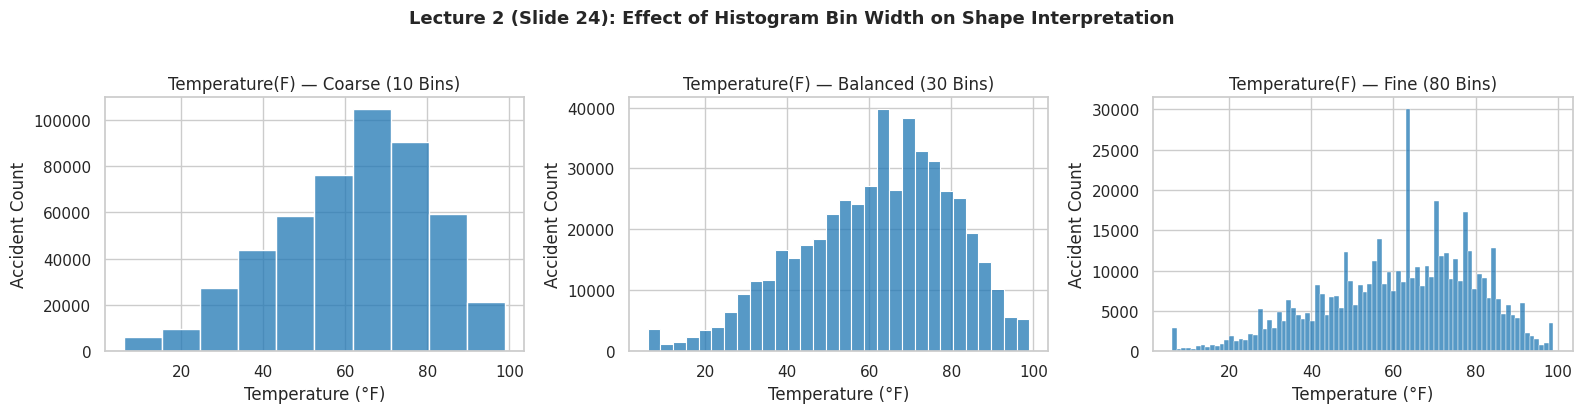

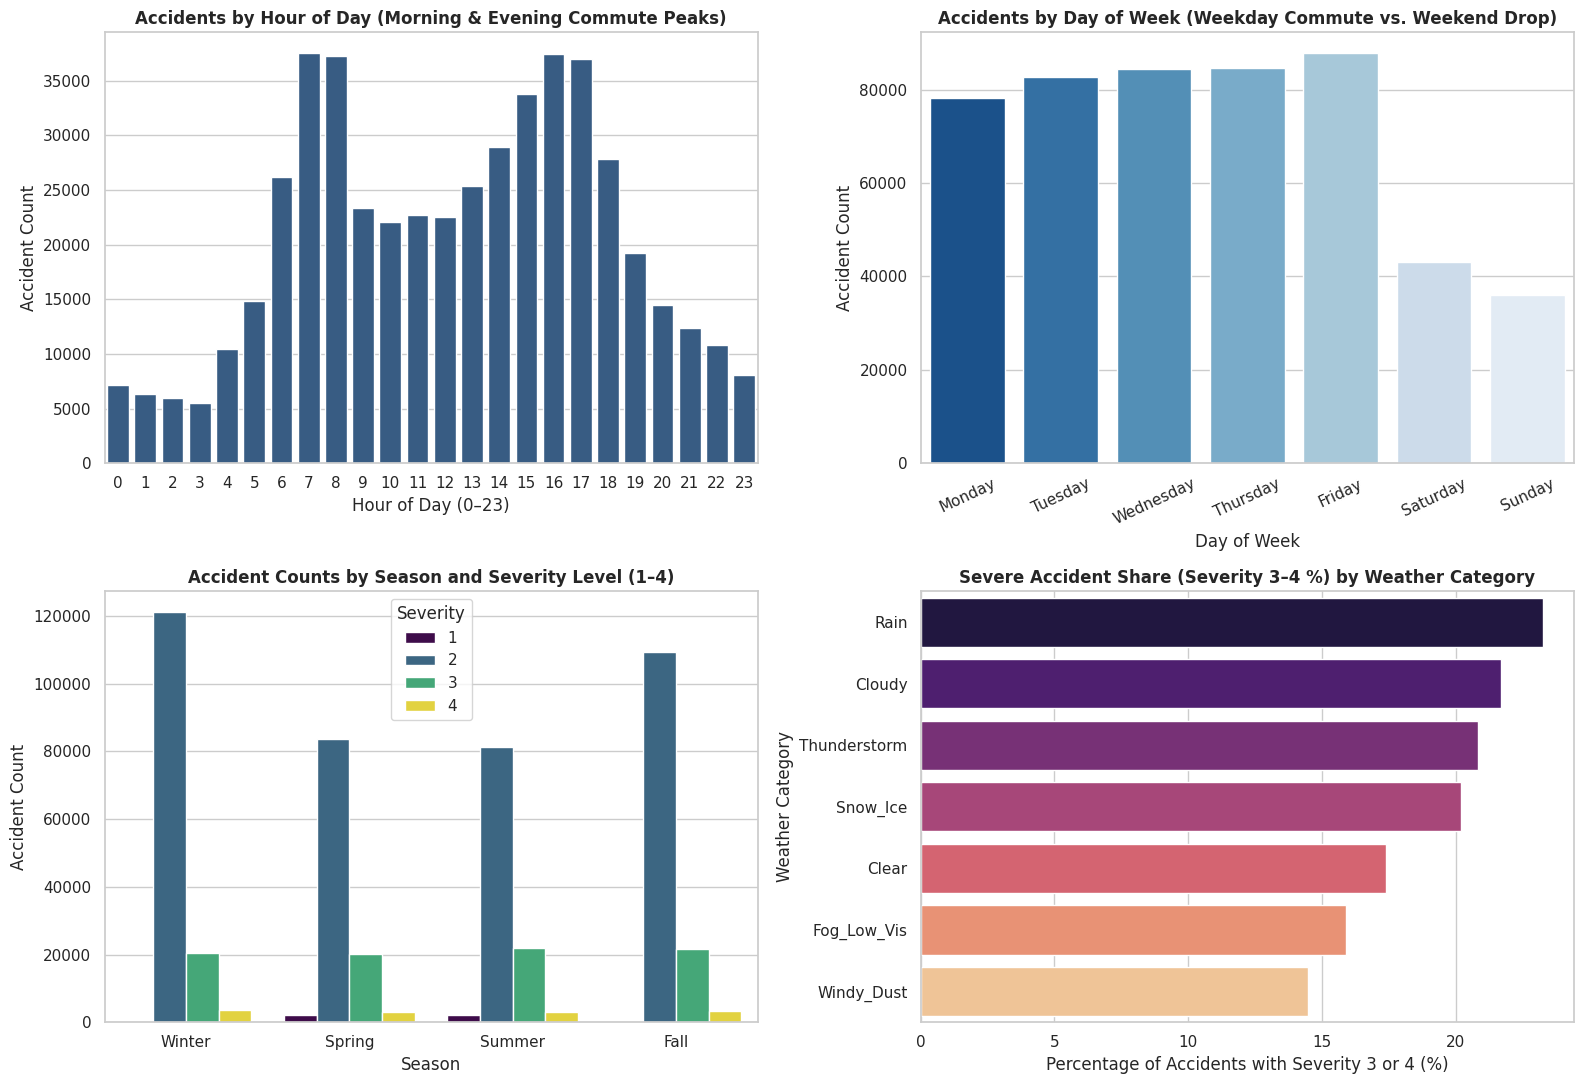

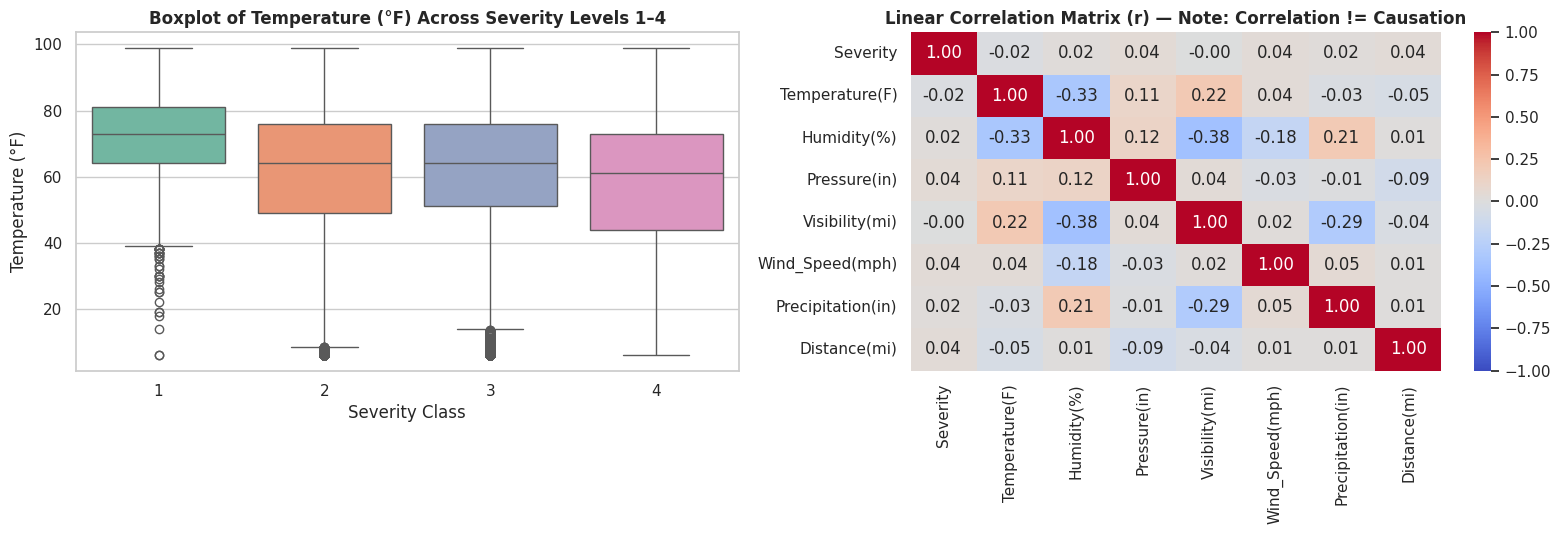

In [ ]:
# 1. Centre, Spread & Shape Summary Table (Lecture 2, Slides 14-22)
summary_cols = ['Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)', 'Distance(mi)']
stat_rows = []
for col in summary_cols:
    s = df[col]
    mean_v, median_v = s.mean(), s.median()
    sd_v = s.std(ddof=1)
    q1_v, q3_v = s.quantile(0.25), s.quantile(0.75)
    iqr_v = q3_v - q1_v
    skew_v = s.skew()
    shape_label = 'Right-Skewed (Mean > Median)' if skew_v > 0.5 else ('Left-Skewed (Mean < Median)' if skew_v < -0.5 else 'Approx. Symmetric')
    stat_rows.append({
        'Attribute': col,
        'Mean': round(mean_v, 3),
        'SD (s)': round(sd_v, 3),
        'Min': round(s.min(), 3),
        'Q1 (25%)': round(q1_v, 3),
        'Median (50%)': round(median_v, 3),
        'Q3 (75%)': round(q3_v, 3),
        'Max': round(s.max(), 3),
        'IQR': round(iqr_v, 3),
        'Skewness': round(skew_v, 2),
        'Distribution Shape & Preferred Centre': shape_label
    })

display(pd.DataFrame(stat_rows))

# 2. Figure 1: Histogram Bin-Width Comparison on Temperature(F) (Lecture 2/3, Slide 24)
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for ax, bins, title in zip(axes, [10, 30, 80], ['Coarse (10 Bins)', 'Balanced (30 Bins)', 'Fine (80 Bins)']):
    sns.histplot(df['Temperature(F)'], bins=bins, kde=False, ax=ax, color='#1f77b4')
    ax.set_title(f"Temperature(F) — {title}")
    ax.set_xlabel("Temperature (°F)")
    ax.set_ylabel("Accident Count")
plt.suptitle("Lecture 2 (Slide 24): Effect of Histogram Bin Width on Shape Interpretation", y=1.03, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. Figure 2: P13 Core EDA — Accident Patterns by Hour, Weekday, Season & Weather
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# (a) By Hour of Day
sns.countplot(data=df, x='Hour', ax=axes[0, 0], color='#2b5c8f')
axes[0, 0].set_title("Accidents by Hour of Day (Morning & Evening Commute Peaks)", fontweight='bold')
axes[0, 0].set_xlabel("Hour of Day (0–23)")
axes[0, 0].set_ylabel("Accident Count")

# (b) By Weekday (Ordered Mon-Sun)
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(data=df, x='Weekday', order=weekday_order, ax=axes[0, 1], palette='Blues_r')
axes[0, 1].set_title("Accidents by Day of Week (Weekday Commute vs. Weekend Drop)", fontweight='bold')
axes[0, 1].set_xlabel("Day of Week")
axes[0, 1].set_ylabel("Accident Count")
axes[0, 1].tick_params(axis='x', rotation=25)

# (c) By Season & Severity Proportion
season_order = ['Winter', 'Spring', 'Summer', 'Fall']
sns.countplot(data=df, x='Season', hue='Severity', order=season_order, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title("Accident Counts by Season and Severity Level (1–4)", fontweight='bold')
axes[1, 0].set_xlabel("Season")
axes[1, 0].set_ylabel("Accident Count")

# (d) High-Severity Rate (Severity 3 or 4 %) by Weather Category
df['High_Severity'] = df['Severity'].isin([3, 4]).astype(int)
weather_sev = df.groupby('Weather_Category')['High_Severity'].mean().sort_values(ascending=False) * 100
sns.barplot(x=weather_sev.values, y=weather_sev.index, ax=axes[1, 1], palette='magma')
axes[1, 1].set_title("Severe Accident Share (Severity 3–4 %) by Weather Category", fontweight='bold')
axes[1, 1].set_xlabel("Percentage of Accidents with Severity 3 or 4 (%)")
axes[1, 1].set_ylabel("Weather Category")

plt.tight_layout()
plt.show()

# 4. Figure 3: Side-by-Side Boxplots & Linear Correlation Heatmap (Lecture 2/3, Slides 21 & 25)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.boxplot(data=df, x='Severity', y='Temperature(F)', ax=axes[0], palette='Set2', showfliers=True)
axes[0].set_title("Boxplot of Temperature (°F) Across Severity Levels 1–4", fontweight='bold')
axes[0].set_xlabel("Severity Class")
axes[0].set_ylabel("Temperature (°F)")

corr_cols = ['Severity', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)', 'Distance(mi)']
corr_matrix = df[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Linear Correlation Matrix (r) — Note: Correlation != Causation", fontweight='bold')

plt.tight_layout()
plt.show()


In [ ]:
print("=" * 75)
print("HYPOTHESIS TEST 1: CHI-SQUARE TEST OF INDEPENDENCE (Weather vs. High Severity)")
print("=" * 75)

contingency_table = pd.crosstab(df['Weather_Category'], df['High_Severity'])
contingency_table.columns = ['Minor (Sev 1-2)', 'Severe (Sev 3-4)']
contingency_table['Severe_Rate (%)'] = (
    contingency_table['Severe (Sev 3-4)'] /
    (contingency_table['Minor (Sev 1-2)'] + contingency_table['Severe (Sev 3-4)']) * 100
).round(2)
display(contingency_table.sort_values(by='Severe_Rate (%)', ascending=False))

chi2_stat, p_val_chi2, dof, _ = stats.chi2_contingency(pd.crosstab(df['Weather_Category'], df['High_Severity']))
n_total = len(df)
cramers_v = np.sqrt(chi2_stat / (n_total * (min(contingency_table.shape[0], 2) - 1)))

print(f"Chi-Square Statistic (χ²) : {chi2_stat:.2f} (df = {dof})")
print(f"p-value                   : {p_val_chi2:.4e}")
print(f"Cramér's V (Effect Size)  : {cramers_v:.4f}")
if p_val_chi2 < 0.05:
    print("Decision (α = 0.05)       : Reject H0 — Accident severity is significantly associated with weather category.")
else:
    print("Decision (α = 0.05)       : Fail to reject H0.")

print("\n" + "=" * 75)
print("HYPOTHESIS TEST 2: TWO-SAMPLE t-TEST & MANN-WHITNEY U (Minor vs. Severe Crashes)")
print("=" * 75)

minor_grp = df[df['High_Severity'] == 0]
severe_grp = df[df['High_Severity'] == 1]

test_results = []
for feature in ['Visibility(mi)', 'Wind_Speed(mph)', 'Temperature(F)']:
    x_minor = minor_grp[feature]
    x_severe = severe_grp[feature]

    t_stat, p_t = stats.ttest_ind(x_severe, x_minor, equal_var=False)
    u_stat, p_u = stats.mannwhitneyu(x_severe, x_minor, alternative='two-sided')

    test_results.append({
        'Feature': feature,
        'Minor Mean (SD)': f"{x_minor.mean():.2f} ({x_minor.std():.2f})",
        'Severe Mean (SD)': f"{x_severe.mean():.2f} ({x_severe.std():.2f})",
        'Observed Gap': round(x_severe.mean() - x_minor.mean(), 3),
        'Welch t-Stat': round(t_stat, 2),
        't-Test p-value': f"{p_t:.3e}",
        'Mann-Whitney p-value': f"{p_u:.3e}",
        'Decision (α=0.05)': 'Reject H0 (Significant)' if p_t < 0.05 else 'Fail to Reject H0'
    })

display(pd.DataFrame(test_results))
print("\nNote (Lecture 2, Slide 28): Statistical significance (p < 0.05) at n = 500k must be interpreted alongside the Observed Gap column to distinguish real practical differences from large-sample sensitivity.")


HYPOTHESIS TEST 1: CHI-SQUARE TEST OF INDEPENDENCE (Weather vs. High Severity)


,Minor (Sev 1-2),Severe (Sev 3-4),Severe_Rate (%)
Weather_Category,,,
Rain,25395,7698,23.26
Cloudy,156869,43479,21.70
Thunderstorm,4571,1202,20.82
Snow_Ice,9234,2339,20.21
Clear,188410,39702,17.40
Fog_Low_Vis,10922,2064,15.89
Windy_Dust,4472,757,14.48


Chi-Square Statistic (χ²) : 1751.49 (df = 6)
p-value                   : 0.0000e+00
Cramér's V (Effect Size)  : 0.0594
Decision (α = 0.05)       : Reject H0 — Accident severity is significantly associated with weather category.

HYPOTHESIS TEST 2: TWO-SAMPLE t-TEST & MANN-WHITNEY U (Minor vs. Severe Crashes)


,Feature,Minor Mean (SD),Severe Mean (SD),Observed Gap,Welch t-Stat,t-Test p-value,Mann-Whitney p-value,Decision (α=0.05)
0,Visibility(mi),9.11 (2.62),9.12 (2.93),0.003,0.34,7.368e-01,1.085e-07,Fail to Reject H0
1,Wind_Speed(mph),7.51 (5.05),8.08 (4.72),0.570,33.34,8.050e-243,1.125e-238,Reject H0 (Significant)
2,Temperature(F),61.74 (18.63),61.74 (18.61),0.002,0.03,9.771e-01,1.716e-01,Fail to Reject H0



Note (Lecture 2, Slide 28): Statistical significance (p < 0.05) at n = 500k must be interpreted alongside the Observed Gap column to distinguish real practical differences from large-sample sensitivity.
